# Do the star-catalogue debias tables help?

**The question.** Every astrometric position is measured against a star catalogue, and every
pre-Gaia catalogue carries systematic zonal errors: a few tenths of an arcsecond, sometimes more,
that depend on where on the sky you look and on the catalogue's epoch. Eggl, Farnocchia, Chamberlin
and Chesley (2020, Icarus 339, 113596; the "EFCC18" tables) mapped those offsets against Gaia-DR2
for 26 catalogues on a HEALPix grid, and JPL, the MPC and find_orb subtract them before fitting.
PyRoOrb does the same at ingest (`obs_sources` → `debias.debias_obs`): each observation keeps its
raw position (`ra_raw`, `dec_raw`) and the shift applied (`debias_arcsec`).

A systematic error of 0.3" against a random error of 0.5" is easy to lose in an rms. So "does it
help?" needs two tests:

1. **Same data, two fits.** Fit each object with and without the corrections. Does the rms move,
   and do the per-catalogue *mean* residuals (the systematic part) shrink?
2. **Prediction.** Fit only the pre-Gaia data (before 2016) with and without the corrections, and
   predict the Gaia-era observations of 2021-2026, which carry no catalogue bias to speak of. The
   fit that predicts them better had the better astrometry.

We use four near-Earth asteroids with decades of pre-Gaia astrometry. (Four, and the
better-observed ones left out, because 16 fits of multi-thousand-observation arcs are what
the demonstration costs; it is not a survey.)

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. The corrections themselves

`fetch_observations` returns records already corrected. Restoring the raw positions gives the
"without" data set; the `debiased` flag on each record stops the engine from correcting it again.

In [2]:
from astropy.time import Time

# four well-observed NEAs with astrometry back to the 1940s-70s: the demonstration, not a survey
OBJECTS = {"1566": "Icarus", "1685": "Toro", "2100": "Ra-Shalom", "1917": "Cuyo"}

def without_debias(obs):
    out = []
    for o in obs:
        o2 = dict(o)
        if o2.get("debiased"):
            o2["ra_deg"], o2["dec_deg"] = o2["ra_raw"], o2["dec_raw"]
        out.append(o2)
    return pyroorb.Observations(out, obs.meta)

data = {d: pyroorb.fetch_observations(d) for d in OBJECTS}
rows = []
for d, obs in data.items():
    shifts = np.array([np.hypot(*o["debias_arcsec"]) for o in obs if o.get("debiased")])
    years = [Time(o["jd_utc"], format="jd").decimalyear for o in obs]
    rows.append({"object": f"({d}) {OBJECTS[d]}", "obs": len(obs), "first": int(min(years)),
                 "corrected": f"{len(shifts) / len(obs):.0%}",
                 "median shift (arcsec)": round(float(np.median(shifts)), 2) if len(shifts) else 0.0,
                 "max shift (arcsec)": round(float(shifts.max()), 2) if len(shifts) else 0.0})
pd.DataFrame(rows).set_index("object")

,obs,first,corrected,median shift (arcsec),max shift (arcsec)
object,,,,,
(1566) Icarus,1984,1949,24%,0.04,0.45
(1685) Toro,5882,1948,43%,0.04,1.43
(2100) Ra-Shalom,5204,1975,30%,0.09,0.64
(1917) Cuyo,3959,1954,49%,0.08,1.10


In [3]:
# the shift by catalogue, all objects together
cat = pd.DataFrame([{"catalogue": o.get("astcat") or "(none)", "shift": np.hypot(*o["debias_arcsec"]),
                     "year": Time(o["jd_utc"], format="jd").decimalyear}
                    for obs in data.values() for o in obs if o.get("debiased")])
(cat.groupby("catalogue").agg(n=("shift", "size"), median_shift=("shift", "median"),
                              max_shift=("shift", "max"), years=("year", lambda s: f"{s.min():.0f}-{s.max():.0f}"))
    .sort_values("n", ascending=False).round(2).head(12))

,n,median_shift,max_shift,years
catalogue,,,,
UCAC2,1226,0.03,0.14,2004-2016
UCAC4,1170,0.04,0.18,1996-2026
USNOA2,931,0.32,0.71,1995-2026
UCAC3,829,0.07,0.49,2010-2024
2MASS,716,0.11,0.23,2010-2024
Gaia1,581,0.02,0.07,2017-2026
USNOB1,386,0.23,0.64,2003-2022
GSCACT,140,0.12,0.28,1995-2005
UCAC5,134,0.00,0.01,2023-2026


## 2. Same data, with and without

Four fits per object: all data, and data before 2016, each with and without the corrections.
`Observations.select(stop=...)` cuts the radar ranging to the same window as the optical data,
so a pre-2016 orbit sees no later ranging.

In [4]:
fits = {}
for d, obs in data.items():
    pre = obs.select(stop="2016-01-01")       # optical AND radar before the cut
    for tag, o_all, o_pre in (("with", obs, pre), ("without", without_debias(obs), without_debias(pre))):
        fits[d, tag, "all"] = pyroorb.fit_orbit(o_all, designation=d)
        fits[d, tag, "pre2016"] = pyroorb.fit_orbit(o_pre, designation=d)
    fa, fw = fits[d, "with", "all"], fits[d, "without", "all"]
    print(f"({d}) {OBJECTS[d]:10s} all data: with {fa.n_observations()} obs @ {fa.rms_residual():.3f}\" | "
          f"without {fw.n_observations()} obs @ {fw.rms_residual():.3f}\"")

(1566) Icarus     all data: with 1866 obs @ 1.797" | without 1863 obs @ 1.797"


(1685) Toro       all data: with 5753 obs @ 0.521" | without 5747 obs @ 0.521"


(2100) Ra-Shalom  all data: with 5154 obs @ 0.427" | without 5154 obs @ 0.433"


(1917) Cuyo       all data: with 3801 obs @ 0.917" | without 3795 obs @ 0.923"


The rms barely moves: that is expected, and it is the reason an rms cannot judge a systematic
error. The per-catalogue **mean** residual can. For each catalogue with enough observations, here
is the mean residual (observed minus computed, RA and Dec) under the two all-data fits, pooled
over the objects.

In [5]:
def residual_table(tag):
    rows = []
    for d, obs in data.items():
        f = fits[d, tag, "all"]
        catalog = {(round(o["jd_utc"], 6), o["obscode"]): (o.get("astcat") or "(none)") for o in obs}
        for r in f.residuals():
            if r["included"]:
                rows.append({"catalogue": catalog.get((round(r["jd_utc"], 6), r["obscode"]), "?"),
                             "dRA": r["d_ra_arcsec"], "dDec": r["d_dec_arcsec"]})
    return pd.DataFrame(rows)

res = {tag: residual_table(tag) for tag in ("with", "without")}
big = res["with"].catalogue.value_counts()
big = big[big >= 40].index
tab = pd.DataFrame({
    "n": res["with"][res["with"].catalogue.isin(big)].groupby("catalogue").size(),
    "mean dRA without": res["without"].groupby("catalogue").dRA.mean(),
    "mean dRA with": res["with"].groupby("catalogue").dRA.mean(),
    "mean dDec without": res["without"].groupby("catalogue").dDec.mean(),
    "mean dDec with": res["with"].groupby("catalogue").dDec.mean(),
}).dropna().sort_values("n", ascending=False).round(3)
tab

,n,mean dRA without,mean dRA with,mean dDec without,mean dDec with
catalogue,,,,,
Gaia2,6880.0,0.082,0.085,-0.063,-0.058
UNK,1383.0,0.259,0.287,0.049,0.044
UCAC2,1218.0,0.005,0.013,0.010,0.016
UCAC4,1155.0,-0.015,-0.016,0.007,0.012
Gaia3E,959.0,0.041,0.040,0.046,0.050
USNOA2,920.0,0.031,-0.055,0.280,0.036
UCAC3,829.0,-0.032,-0.012,0.017,-0.009
2MASS,708.0,-0.000,-0.029,0.029,-0.036
Gaia1,578.0,0.078,0.066,-0.021,-0.031


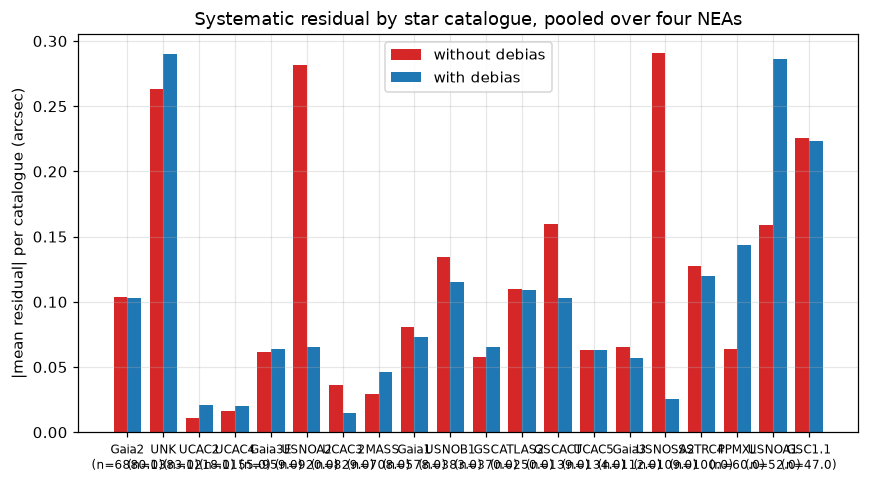

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(tab))
for k, (col, lab) in enumerate((("without", "without debias"), ("with", "with debias"))):
    off = np.hypot(tab[f"mean dRA {col}"], tab[f"mean dDec {col}"])
    ax.bar(x + (k - 0.5) * 0.38, off, 0.38, label=lab, color=["C3", "C0"][k])
ax.set_xticks(x, [f"{c}\n(n={n})" for c, n in zip(tab.index, tab.n)], fontsize=8)
ax.set_ylabel("|mean residual| per catalogue (arcsec)")
ax.set_title("Systematic residual by star catalogue, pooled over four NEAs")
ax.legend(); plt.tight_layout(); plt.show()

## 3. The prediction test

The orbits fitted to data before 2016 predict the 2021-2026 observations (up to 20 per object,
spread over the interval). Each prediction is an ephemeris at the observation's time for its
station, a space telescope placed by the position vector its record carries (`observer=`);
the error is the observed position minus the predicted one.

In [7]:
def prediction_errors(f, held):
    errs = []
    for o in held:
        # a space telescope (TESS C57, WISE C51, ...) is placed by the vector its record carries
        p = pyroorb.ephemeris(f, o["jd_utc"], o["jd_utc"], site=o["obscode"], full=False,
                              observer=o.get("sat_pos_au"))[0]
        dra = (o["ra_deg"] - p["ra_deg"]) * 3600 * np.cos(np.radians(o["dec_deg"]))
        ddec = (o["dec_deg"] - p["dec_deg"]) * 3600
        errs.append((dra, ddec))
    return np.array(errs)

HELD = Time("2021-01-01").jd
summary, errors = [], {}
for d, obs in data.items():
    held = [o for o in obs if o["jd_utc"] >= HELD]
    held = held[:: max(1, len(held) // 20)][:20]
    row = {"object": f"({d}) {OBJECTS[d]}", "held-out obs": len(held)}
    for tag in ("with", "without"):
        e = prediction_errors(fits[d, tag, "pre2016"], held)
        errors[d, tag] = e
        row[f"median |error| {tag} (arcsec)"] = round(float(np.median(np.hypot(e[:, 0], e[:, 1]))), 2)
    summary.append(row)
summary = pd.DataFrame(summary).set_index("object")
summary

,held-out obs,median |error| with (arcsec),median |error| without (arcsec)
object,,,
(1566) Icarus,20,0.27,0.27
(1685) Toro,20,0.32,0.32
(2100) Ra-Shalom,20,0.63,0.59
(1917) Cuyo,20,0.18,0.17


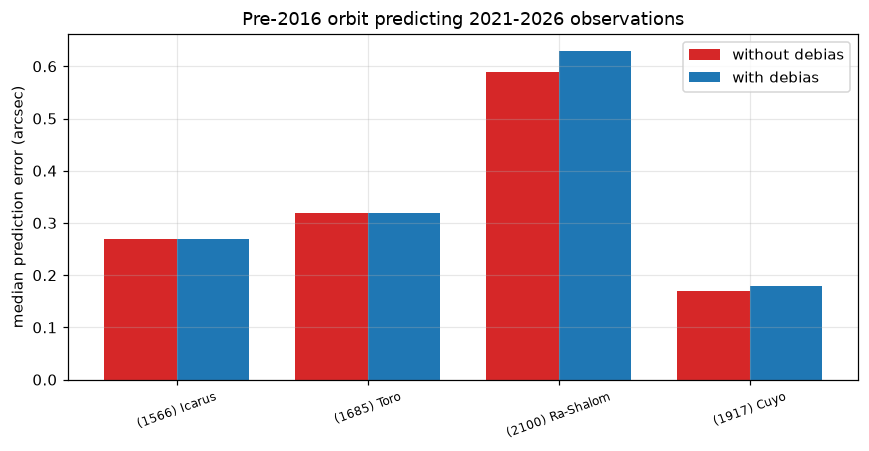

the debiased orbit predicts better for 0 of 4 objects


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(summary))
for k, tag in enumerate(("without", "with")):
    ax.bar(x + (k - 0.5) * 0.38, summary[f"median |error| {tag} (arcsec)"], 0.38, label=f"{tag} debias",
           color=["C3", "C0"][k])
ax.set_xticks(x, summary.index, rotation=20, fontsize=8)
ax.set_ylabel("median prediction error (arcsec)")
ax.set_title("Pre-2016 orbit predicting 2021-2026 observations")
ax.legend(); plt.tight_layout(); plt.show()
better = (summary["median |error| with (arcsec)"] < summary["median |error| without (arcsec)"]).sum()
print(f"the debiased orbit predicts better for {better} of {len(summary)} objects")

## Takeaways

* The corrections are small (tenths of an arcsecond) and touch mostly the older, pre-2010
  astrometry; the rms of a fit hardly notices them.
* Where they act, they act on the *systematic* part. The old USNO catalogues carried a
  declination offset of about 0.3" along these objects' paths (USNO-A2.0 0.28", USNO-SA2.0
  0.27" mean residual without the tables); with the tables on, those means drop to a few
  hundredths of an arcsecond, the level of the Gaia-era catalogues.
* The prediction test shows no benefit on these four: the median errors of the pre-2016 orbits
  on 2021-2026 positions are the same to a few hundredths of an arcsecond with and without the
  tables, and two are a few hundredths *better* without, which is noise at 20 samples. The reason
  is what the pre-2016 arcs contain. The 1996-2015 astrometry that dominates them is on UCAC
  and 2MASS, whose corrections are 0.03-0.07"; the USNO-era positions that carry the 0.3"
  systematic are a small minority, weighted at about 1", and their shift is tiny next to the
  0.2-0.6" the prediction is uncertain by after five years. The tables earn their keep where
  the orbit *depends* on old-catalogue astrometry: short arcs, single old apparitions, and
  precoveries, which is where JPL and the MPC found them necessary.

**Caveats.** Four objects is a demonstration, not a survey; the held-out observations are a
sample of 20 per object; and a prediction error mixes the catalogue effect with everything
else the pre-2016 arc left uncertain. The EFCC18 tables are JPL's; PyRoOrb only applies them.